In [2]:
# Cell 2: Library Setup & Visualization Configurations
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual aesthetic for publication-grade charts
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [3]:
# Cell 4: Download Historical Data & Compute Daily Returns
tickers = ['AAPL', 'MSFT', 'NVDA']
weights = np.array([0.40, 0.30, 0.30])  # Portfolio weights: 40% AAPL, 30% MSFT, 30% NVDA
initial_investment = 100000             # Portfolio value in USD

# Retrieve daily closing prices
data = yf.download(tickers, start="2021-01-01", end="2024-01-01")['Close']
returns = data.pct_change().dropna()

# Display mean daily returns and covariance matrix
print("Mean Daily Returns:")
print(returns.mean())
print("\nCovariance Matrix:")
print(returns.cov())

[*********************100%***********************]  3 of 3 completed


Mean Daily Returns:
Ticker
AAPL    0.000705
MSFT    0.000916
NVDA    0.002320
dtype: float64

Covariance Matrix:
Ticker      AAPL      MSFT      NVDA
Ticker                              
AAPL    0.000307  0.000222  0.000367
MSFT    0.000222  0.000307  0.000396
NVDA    0.000367  0.000396  0.001115


In [4]:
# Cell 6: Cholesky Factorization & 10,000-Scenario Simulation
mean_returns = returns.mean()
cov_matrix = returns.cov()

# Lower triangular matrix via Cholesky decomposition
cholesky_matrix = np.linalg.cholesky(cov_matrix)

# Simulation Parameters
num_simulations = 10000
np.random.seed(42)  # Seed for exact reproducibility

# Generate independent standard normal random variables
Z = np.random.normal(size=(num_simulations, len(tickers)))

# Apply Cholesky transformation to introduce realistic asset co-movements
simulated_daily_returns = np.dot(Z, cholesky_matrix.T) + mean_returns.values

# Compute aggregate portfolio returns across all simulated scenarios
portfolio_returns = np.dot(simulated_daily_returns, weights)

# Calculate dollar loss per scenario (Loss = Initial Investment - Simulated Portfolio Value)
portfolio_losses = initial_investment * (1 - (1 + portfolio_returns))

In [5]:
# Cell 8: Compute Risk Metrics
var_95 = np.percentile(portfolio_losses, 95)
var_99 = np.percentile(portfolio_losses, 99)
cvar_95 = portfolio_losses[portfolio_losses >= var_95].mean()

print("=" * 45)
print("             RISK DESK REPORT               ")
print("=" * 45)
print(f"Initial Portfolio Value : ${initial_investment:,.2f}")
print(f"1-Day 95% VaR           : ${var_95:,.2f}")
print(f"1-Day 99% VaR           : ${var_99:,.2f}")
print(f"1-Day 95% CVaR (ES)     : ${cvar_95:,.2f}")
print("=" * 45)

             RISK DESK REPORT               
Initial Portfolio Value : $100,000.00
1-Day 95% VaR           : $3,093.17
1-Day 99% VaR           : $4,326.02
1-Day 95% CVaR (ES)     : $3,889.64


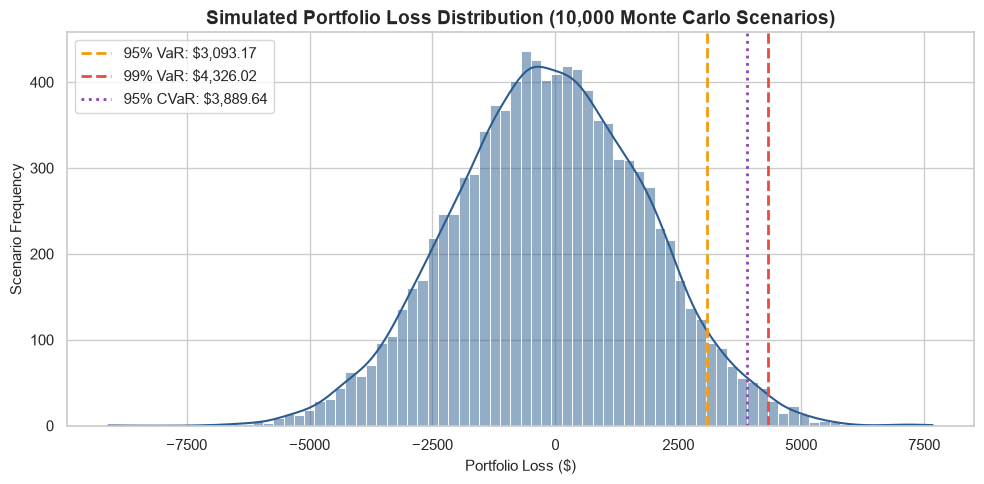

In [6]:
# Cell 10: Plot Simulated Loss Distribution
plt.figure(figsize=(10, 5))
sns.histplot(portfolio_losses, bins=80, kde=True, color='#2b5c8f')

# Highlight risk thresholds
plt.axvline(var_95, color='#f39c12', linestyle='--', linewidth=2, label=f'95% VaR: ${var_95:,.2f}')
plt.axvline(var_99, color='#e74c3c', linestyle='--', linewidth=2, label=f'99% VaR: ${var_99:,.2f}')
plt.axvline(cvar_95, color='#8e44ad', linestyle=':', linewidth=2, label=f'95% CVaR: ${cvar_95:,.2f}')

plt.title('Simulated Portfolio Loss Distribution (10,000 Monte Carlo Scenarios)', fontsize=14, fontweight='bold')
plt.xlabel('Portfolio Loss ($)', fontsize=11)
plt.ylabel('Scenario Frequency', fontsize=11)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()